# How often training samples repeat on the `flopsonly` branch

`flopsonly` has no seeding. It is like the upstream repo in terms of determinism. It has no `cfg.seed` hydra param, no `seed_all` method, and no per-epoch re-seeding. We work out, for PT9 pretraining, how likely each part of a training sample is to repeat in the following ways:

1. the dataset order: which dataset each micro-batch comes from
2. the window: trajectory and initial frame $t_0$
3. the time stride $dt$: given the window
4. the identical sample: same window, same $dt$ and the same 90° rotation.

For each repetition method, we calculate the repetition in three ways; a closed-form probability, a CPU simulation of 100 epochs on 4 GPUs, and the per-sample draw logs of four GPU jobs (two straight runs, two stopped and resumed generated from `gen_pt9_determinism_runs.py`). In the last section, we comapre the GPU jobs' weights.

#### What is the source of each level of choice on `flopsonly`?

| choice | drawn by | random stream | granularity |
|---|---|---|---|
| dataset | `BatchedMultisetSampler` (`walrus/data/mixed_dset_sampler.py`) | `torch.Generator` seeded with $100 \cdot \text{epoch} + \text{rank}_\text{sampling}$; the sampling rank is 0 on every GPU under fsdp | per micro-batch |
| window | one `RandomSampler` per dataset | seeded from the global torch RNG at first use, which starts from OS entropy | per sample |
| $dt$ | the_well `WellDataset._load_one_sample`, in a DataLoader worker | `np.random`, seeded by PyTorch per worker from a per-epoch base seed (OS entropy) | per sample |
| rotation | the_well `RandomRotation90`, in a DataLoader worker | `np.random`, as above | per micro-batch |

Probabilities are given at sweep scale: N1 (4 GPUs), `max_samples=2000` micro-batches of 2
windows per GPU per epoch, at 60 and 100 epochs, on the nine PT9 datasets.

In [1]:
import glob
import json
import subprocess
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

HERE = Path.cwd()                      # LeonardoRunScripts/PT9_2d/Determinism
REPO = HERE.parents[2]
sys.path[:0] = [str(REPO / "scripts"), str(HERE.parent), str(HERE)]

import walrus
import walrus.data.mixed_dset_sampler as mds
from gen_pt9_determinism_runs import RUN_ROOT
from pt9_substrate import PRETRAIN_DATASETS
from the_well.data.augmentation import PROPER_3D_ROTATIONS
from the_well.data.utils import maximum_stride_for_initial_index
from well_registry import load_registry, n_windows

branch = subprocess.run(["git", "-C", str(REPO), "rev-parse", "--abbrev-ref", "HEAD"], capture_output=True, text=True).stdout.strip()
print("branch:", branch, "| walrus from", walrus.__file__)
assert branch == "flopsonly"

pd.options.display.float_format = "{:,.4g}".format
N_IN, N_OUT, MIN_DT, MAX_DT = 6, 1, 1, 5          # PT9 substrate
BATCH, MAX_SAMPLES, GPUS, EPOCHS = 2, 2000, 4, (60, 100)
CODE = {
    "acoustic_scattering_discontinuous": "AD", "acoustic_scattering_inclusions": "AI",
    "acoustic_scattering_maze": "AM", "euler_multi_quadrants_openBC": "EMQ-O",
    "euler_multi_quadrants_periodicBC": "EMQ-P", "gray_scott_reaction_diffusion": "GS",
    "planetswe": "PS", "rayleigh_benard": "RB", "shear_flow": "SF",
}
K = len(PRETRAIN_DATASETS)
reg = load_registry()["datasets"]

branch: flopsonly | walrus from /leonardo/home/userexternal/sshamsi0/MHPC_Thesis/walrus/__init__.py


## 0. Windows and their maximum stride

A window is one trajectory and one initial frame $t_0$. the_well counts windows at the minimum
stride, so a trajectory of $T$ steps has $T - (N_\text{in} + N_\text{out}) + 1 = T - 6$ windows.
At draw time $dt$ is uniform on $\{1, \dots, m(t_0)\}$, with

$$
m(t_0) = \min\!\left(5,\ \left\lfloor \frac{T - 1 - t_0}{N_\text{in} + N_\text{out} - 1} \right\rfloor\right),
$$

and $dt = 1$ whenever $m(t_0) \le 1$. Near the end of a trajectory fewer strides fit.

In [2]:
def windows(name):
    # t0 and trajectory length T of every train window, in the_well's order of counting.
    groups = reg[name]["splits"]["train"]["steps"]
    t0 = np.concatenate([np.tile(np.arange(g["n_steps"] - N_IN - N_OUT + 1), g["n_traj"]) for g in groups])
    T = np.concatenate([np.full((g["n_steps"] - N_IN - N_OUT + 1) * g["n_traj"], g["n_steps"]) for g in groups])
    return t0, T

def max_dt(t0, T):
    m = np.minimum(MAX_DT, np.maximum(0, (T - 1 - t0) // (N_IN + N_OUT - 1)))
    return np.where(m > MIN_DT, m, MIN_DT)

WIN = {}
for name in PRETRAIN_DATASETS:
    t0, T = windows(name)
    assert len(t0) == n_windows(reg[name]["splits"]["train"], N_IN, N_OUT, MIN_DT)
    m = max_dt(t0, T)
    for i in np.random.default_rng(0).choice(len(t0), 200):   # the formula is the_well's
        ref = min(maximum_stride_for_initial_index(int(t0[i]), int(T[i]), N_IN, N_OUT), MAX_DT)
        assert m[i] == (ref if ref > MIN_DT else MIN_DT)
    WIN[CODE[name]] = {"t0": t0, "T": T, "m": m}
pd.Series({c: len(w["t0"]) for c, w in WIN.items()}, name="train windows W")

AD       153600
AI       268608
AM       313600
EMQ-O    380000
EMQ-P    380000
GS       955200
PS        96192
RB       271600
SF       173824
Name: train windows W, dtype: int64

## 1. Dataset order

The dataset of each micro-batch comes from a `torch.Generator` seeded with
$100 \cdot \text{epoch} + 10 \cdot 0 + \text{rank}_\text{sampling}$. Under fsdp the sampling rank
is 0 on every GPU. So the dataset sequence of an epoch is fixed by the epoch number alone:

- **the same on all 4 GPUs at every step**;
- **the same in every run**, whatever else differs;
- **the same after a resume**, because epoch $E$ is drawn the same way whether or not the job was
  restarted.

The probability that two runs, two GPUs, or a resumed and an uninterrupted epoch see the same
dataset order is therefore **1**. Across epochs the orders differ. Each epoch gives every dataset
a multinomial share of the 2000 micro-batches, with mean $2000/9 \approx 222$.

Check: rebuild the order from that formula, and compare it with the real sampler's.

In [3]:
def dataset_order(epoch, rank=0, n=MAX_SAMPLES):
    g = torch.Generator()
    g.manual_seed(int(100 * epoch + 10 * 0 + rank))
    return np.array([int(torch.randint(0, K, (1,), generator=g)) for _ in range(n)])

class Mixed:  # the three attributes BatchedMultisetSampler reads, with PT9's real window counts
    sub_dsets = [range(len(WIN[CODE[n]]["t0"])) for n in PRETRAIN_DATASETS]
    offsets = list(np.cumsum([0] + [len(WIN[CODE[n]]["t0"]) for n in PRETRAIN_DATASETS[:-1]]))
    effective_batch_sizes = [1.0] * K

sampler = mds.BatchedMultisetSampler(Mixed(), torch.utils.data.RandomSampler, BATCH, max_samples=MAX_SAMPLES, rank=0)
for epoch in (1, 2, 3):
    sampler.set_epoch(epoch)
    real = np.array([np.searchsorted(Mixed.offsets, b[0], side="right") - 1 for b in sampler])
    assert (real == dataset_order(epoch)).all()
print("the real sampler's dataset order equals the formula for epochs 1-3")

ORDER = {e: dataset_order(e) for e in range(1, max(EPOCHS) + 1)}
counts = np.array([np.bincount(ORDER[e], minlength=K) for e in ORDER])
pd.DataFrame({"mean micro-batches per epoch": counts.mean(0), "min": counts.min(0), "max": counts.max(0)},
             index=[CODE[n] for n in PRETRAIN_DATASETS])

the real sampler's dataset order equals the formula for epochs 1-3


,mean micro-batches per epoch,min,max
AD,224.8,193,273
AI,223.4,196,256
AM,220.3,191,246
EMQ-O,225.2,178,262
EMQ-P,221.2,182,257
GS,221.2,193,254
PS,220.4,185,248
RB,221.6,182,252
SF,222,194,253


## 2. Windows

Call one GPU in one epoch a **unit**. Within a unit, each dataset's `RandomSampler` hands out a
fresh permutation, so **no window repeats within a unit**. That holds as long as the unit draws
fewer windows than the dataset has, which is true here by a factor of at least 27. Different units
draw independently: each epoch starts new permutations, from OS-entropy seeds, on every GPU.

For dataset $d$ with $W_d$ windows, a unit draws $k_d = 2 n_d$ windows, so a given window is drawn
in a unit with probability $p_d = k_d / W_d$. Over $U = 4E$ units:

- **expected draws per window:** $\lambda_d = U p_d$;
- **coverage**, the fraction of windows drawn at least once: $1 - (1 - p_d)^U$;
- **probability that a draw repeats an earlier draw:**
  $1 - \dfrac{1 - (1 - p_d)^U}{U p_d}$, which is one minus distinct draws over all draws.

Across the 4 GPUs within one epoch, the expected number of windows drawn by two or more GPUs is
$W_d \left[1 - (1 - p_d)^4 - 4 p_d (1 - p_d)^3\right]$.

A **resumed** epoch is just another unit with fresh permutations. It repeats an earlier window with
the same probability as any other unit, and it replays nothing. The CPU check in the earlier
analysis found 0.20% overlap with the first launch's epoch 1, against 0.12–0.18% between unrelated
epochs.

In [4]:
k_mean = 2 * counts.mean(0)          # windows per unit, per dataset
rows = {}
for d, name in enumerate(PRETRAIN_DATASETS):
    c, W = CODE[name], len(WIN[CODE[name]]["t0"])
    p = k_mean[d] / W
    row = {"W": W, "k per unit": k_mean[d], "p per unit": p,
           "multi-GPU windows per epoch": W * (1 - (1 - p) ** 4 - 4 * p * (1 - p) ** 3)}
    for E in EPOCHS:
        U = GPUS * E
        row[f"draws per window @{E}"] = U * p
        row[f"coverage @{E}"] = 1 - (1 - p) ** U
        row[f"P(repeat) @{E}"] = 1 - (1 - (1 - p) ** U) / (U * p)
    rows[c] = row
window_table = pd.DataFrame(rows).T
assert (window_table["k per unit"] * 27 < window_table["W"]).all()   # no recycling within a unit
window_table

,W,k per unit,p per unit,multi-GPU windows per epoch,draws per window @60,coverage @60,P(repeat) @60,draws per window @100,coverage @100,P(repeat) @100
AD,1.536e+05,449.5,0.002926,7.862,0.7023,0.5051,0.2809,1.171,0.6903,0.4103
AI,2.686e+05,446.7,0.001663,4.448,0.3991,0.3293,0.1749,0.6652,0.4861,0.2692
AM,3.136e+05,440.5,0.001405,3.706,0.3371,0.2864,0.1506,0.5619,0.4301,0.2346
EMQ-O,3.8e+05,450.4,0.001185,3.198,0.2845,0.2477,0.1292,0.4741,0.3777,0.2033
EMQ-P,3.8e+05,442.4,0.001164,3.086,0.2794,0.2439,0.1271,0.4657,0.3725,0.2002
GS,9.552e+05,442.4,0.0004631,1.228,0.1111,0.1052,0.05336,0.1852,0.1691,0.08697
PS,9.619e+04,440.9,0.004584,12.05,1.1,0.668,0.3928,1.833,0.8408,0.5414
RB,2.716e+05,443.2,0.001632,4.329,0.3916,0.3242,0.172,0.6527,0.4796,0.2651
SF,1.738e+05,444,0.002554,6.781,0.613,0.4587,0.2517,1.022,0.6405,0.3731


## 3. $dt$ given the window

The window is drawn uniformly, then $dt$ is uniform on $\{1, \dots, m(t_0)\}$. So

$$
P(dt = j) = \frac{1}{W} \sum_{w} \frac{\mathbb{1}[j \le m(t_0^w)]}{m(t_0^w)}, \qquad
P(\text{same } dt \mid \text{same window}) = \frac{1}{W} \sum_w \frac{1}{m(t_0^w)}.
$$

Most windows allow all five strides. Only the last $\approx 24$ frames of each trajectory allow fewer.

In [5]:
dt_rows = {}
for c, w in WIN.items():
    m = w["m"]
    row = {f"P(dt={j})": np.mean((j <= m) / m) for j in range(1, MAX_DT + 1)}
    row["P(same dt | same window)"] = np.mean(1 / m)
    dt_rows[c] = row
dt_table = pd.DataFrame(dt_rows).T
dt_table

,P(dt=1),P(dt=2),P(dt=3),P(dt=4),P(dt=5),P(same dt | same window)
AD,0.2802,0.2177,0.1865,0.1656,0.15,0.2802
AI,0.2802,0.2177,0.1865,0.1656,0.15,0.2802
AM,0.2393,0.2087,0.1934,0.1832,0.1755,0.2393
EMQ-O,0.2811,0.2179,0.1863,0.1653,0.1495,0.2811
EMQ-P,0.2811,0.2179,0.1863,0.1653,0.1495,0.2811
GS,0.2077,0.2017,0.1987,0.1967,0.1952,0.2077
PS,0.2077,0.2017,0.1987,0.1967,0.1952,0.2077
RB,0.2397,0.2088,0.1933,0.183,0.1753,0.2397
SF,0.2397,0.2088,0.1933,0.183,0.1753,0.2397


## 4. Rotation

`RandomRotation90` draws **one** rotation per micro-batch, so both samples of a micro-batch share it.
2D data is padded to 3D first, so it draws from the **24** proper 3D rotations, not the 4 planar ones.
Several of these move the singleton axis into the plane, and some flip only the singleton axis,
which does nothing. Applying all 24 to an asymmetric $3 \times 4 \times 1$ array shows how many
*distinct* orientations a 2D sample can end up in. PS is on an equiangular grid, which the
transform skips: PS is never rotated.

$P(\text{same orientation}) = \sum_c (n_c / 24)^2$, summed over the distinct outcomes $c$.

In [6]:
probe = np.arange(12).reshape(3, 4, 1)
outcomes = {}
for i, (perm, mask) in enumerate(PROPER_3D_ROTATIONS):     # permute, then flip (RandomRotation90.rotate90)
    out = np.transpose(probe, perm)
    for axis, flip in enumerate(mask):
        if flip:
            out = np.flip(out, axis)
    outcomes.setdefault((out.shape, out.tobytes()), []).append(i)
class_of = np.empty(len(PROPER_3D_ROTATIONS), int)
for c, members in enumerate(outcomes.values()):
    class_of[members] = c
sizes = np.array([len(v) for v in outcomes.values()])
P_SAME_ROT = float(((sizes / 24) ** 2).sum())
print(f"{len(sizes)} distinct orientations from 24 rotations (class sizes {sorted(sizes)}); "
      f"P(same orientation) = {P_SAME_ROT:.4f}")

24 distinct orientations from 24 rotations (class sizes [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]); P(same orientation) = 0.0417


## 5. Identical samples

A draw is an exact repeat if an earlier draw had the same window, the same $dt$ and the same
orientation. Given the window, those last two match with probability
$q_w = \rho / m(t_0^w)$, where $\rho = P(\text{same orientation})$ ($\rho = 1$ for PS). Treating each
unit as independent,

$$
P(\text{identical repeat}) = 1 - \frac{1}{W} \sum_w \frac{1 - (1 - p\, q_w)^U}{U p\, q_w}.
$$

In [7]:
def p_identical(c, d, E):
    U, p = GPUS * E, k_mean[d] / len(WIN[c]["t0"])
    q = (1.0 if c == "PS" else P_SAME_ROT) / WIN[c]["m"]
    return 1 - np.mean((1 - (1 - p * q) ** U) / (U * p * q))

ident = pd.DataFrame({f"P(identical) @{E}": {CODE[n]: p_identical(CODE[n], d, E) for d, n in enumerate(PRETRAIN_DATASETS)}
                      for E in EPOCHS})
formula = pd.concat([window_table[[f"P(repeat) @{E}" for E in EPOCHS]], ident], axis=1)
formula

,P(repeat) @60,P(repeat) @100,P(identical) @60,P(identical) @100
AD,0.2809,0.4103,0.004066,0.00677
AI,0.1749,0.2692,0.002315,0.003859
AM,0.1506,0.2346,0.001671,0.002787
EMQ-O,0.1292,0.2033,0.001656,0.002761
EMQ-P,0.1271,0.2002,0.001627,0.002713
GS,0.05336,0.08697,0.0004789,0.0007992
PS,0.3928,0.5414,0.105,0.1666
RB,0.172,0.2651,0.001944,0.003241
SF,0.2517,0.3731,0.00304,0.005065


## 6. CPU simulation: 100 epochs on 4 GPUs

This simulates every draw, using the real dataset order of §1. For each GPU and epoch, each dataset
gets $2 n_d$ windows drawn without replacement. Each sample gets $dt$ uniform on
$\{1, \dots, m(t_0)\}$. Each micro-batch gets one of the 24 rotations, shared by its two samples
(none for PS). Repeats are counted as all draws minus distinct ones, which doesn't depend on order.

In [8]:
rng = np.random.default_rng(1)
draws = {c: [] for c in WIN}            # per dataset: (epoch, window, dt, orientation) of every draw
for e in range(1, max(EPOCHS) + 1):
    n_mb = np.bincount(ORDER[e], minlength=K)
    for gpu in range(GPUS):
        for d, name in enumerate(PRETRAIN_DATASETS):
            c, W = CODE[name], len(WIN[CODE[name]]["t0"])
            win = rng.choice(W, 2 * n_mb[d], replace=False)
            dt = 1 + (rng.random(len(win)) * WIN[c]["m"][win]).astype(int)
            rot = np.full(len(win), -1) if c == "PS" else np.repeat(class_of[rng.integers(0, 24, n_mb[d])], 2)
            draws[c].append(np.stack([np.full(len(win), e), win, dt, rot], 1))
draws = {c: np.concatenate(v) for c, v in draws.items()}

sim = {}
for c, a in draws.items():
    row = {}
    for E in EPOCHS:
        b = a[a[:, 0] <= E]
        row[f"P(repeat) @{E}"] = 1 - len(np.unique(b[:, 1])) / len(b)
        row[f"P(identical) @{E}"] = 1 - len(np.unique(b[:, 1:], axis=0)) / len(b)
    sim[c] = row
sim = pd.DataFrame(sim).T
compare = pd.concat({"formula": formula, "simulation": sim[formula.columns]}, axis=1).swaplevel(axis=1).sort_index(axis=1)
compare

P(identical) @100            P(identical) @60            P(repeat) @100  \
                formula simulation          formula simulation        formula   
AD              0.00677   0.006557         0.004066   0.003927         0.4103   
AI             0.003859   0.003979         0.002315   0.002469         0.2692   
AM             0.002787   0.002889         0.001671   0.001746         0.2346   
EMQ-O          0.002761    0.00277         0.001656   0.001683         0.2033   
EMQ-P          0.002713   0.002684         0.001627   0.001675         0.2002   
GS            0.0007992  0.0008251        0.0004789   0.000471        0.08697   
PS               0.1666     0.1672            0.105     0.1061         0.5414   
RB             0.003241   0.003182         0.001944   0.001898         0.2651   
SF             0.005065   0.005045          0.00304   0.003007         0.3731   

                 P(repeat) @60             
      simulation       formula simulation  
AD        0.4099        0.2809     0.2779  
AI        0.2704        0.1749      0.177  
AM        0.2343        0.1506      0.151  
EMQ-O     0.2039        0.1292     0.1303  
EMQ-P     0.2001        0.1271     0.1282  
GS       0.08677       0.05336    0.05378  
PS        0.5421        0.3928     0.3946  
RB        0.2661         0.172     0.1727  
SF        0.3722        0.2517      0.251

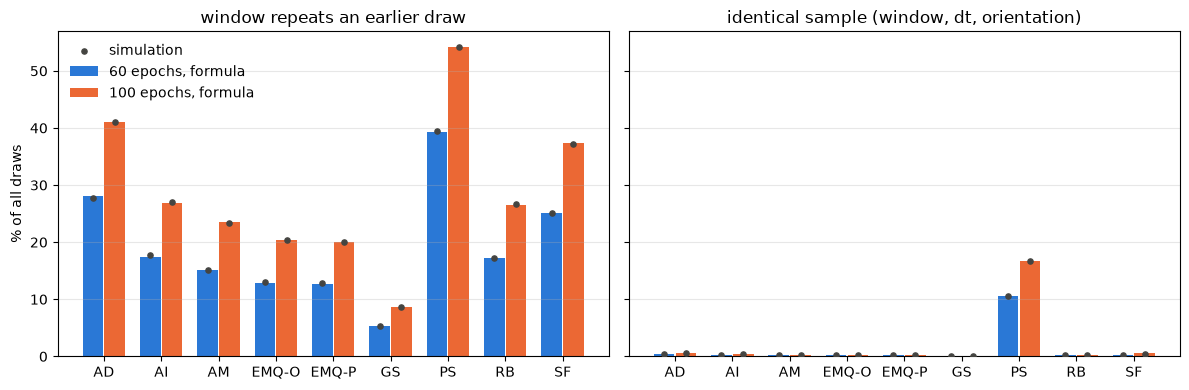

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
x = np.arange(len(formula))
for ax, kind in zip(axes, ["repeat", "identical"]):
    for i, E in enumerate(EPOCHS):
        col = f"P({kind}) @{E}"
        ax.bar(x + (i - 0.5) * 0.38, formula[col] * 100, 0.36, color=["#2a78d6", "#eb6834"][i], label=f"{E} epochs, formula")
        ax.scatter(x + (i - 0.5) * 0.38, sim[col] * 100, color="#444441", s=14, zorder=3,
                   label="simulation" if i == 0 else None)
    ax.set_xticks(x, formula.index)
    ax.set_title("window repeats an earlier draw" if kind == "repeat" else "identical sample (window, dt, orientation)")
    ax.grid(alpha=0.3, axis="y")
axes[0].set_ylabel("% of all draws")
axes[0].legend(frameon=False)
fig.tight_layout()

## 7. The GPU jobs' draw logs

Four jobs on `flopsonly` (`gen_pt9_determinism_runs.py`): tiny model, 4 GPUs, 2 epochs of 100
micro-batches each. A1 and A2 train straight through. B1 and B2 train, then resume from epoch 1
and redo epoch 2. With `WALRUS_DRAW_LOG` set, every DataLoader worker logged one row per training
sample. A row's micro-batch number is $\text{seq} \times n_\text{workers} + \text{worker}$, since the
DataLoader hands batches to workers in turn. Its launch is the training process (`launch`), and the
first launch is the one that ran epoch 1.

In [10]:
logs = []
for run in ("A1", "A2", "B1", "B2"):
    for f in glob.glob(f"{RUN_ROOT}/{run}/draws/*.csv"):
        logs.append(pd.read_csv(f).assign(run=run))
log = pd.concat(logs, ignore_index=True)
log["code"] = log.dataset.map({n: c for n, c in CODE.items()})
log["batch"] = log.seq * log.n_workers + log.worker
first = log.groupby(["run", "rank", "launch"]).epoch.transform("min") == 1
log["attempt"] = np.where(first, "first", "resumed")
log["slot"] = log.groupby(["run", "attempt", "epoch", "rank", "batch"]).cumcount()   # position in the micro-batch
log.groupby(["run", "attempt", "epoch"]).size().unstack("epoch")

epoch         1   2
run attempt        
A1  first   800 800
A2  first   800 800
B1  first   800 800
    resumed NaN 800
B2  first   800 800
    resumed NaN 800

In [11]:
# (a) Dataset order: the same on every GPU, in every run and attempt, and equal to the formula.
per_batch = log.groupby(["run", "attempt", "epoch", "batch"]).code.agg(lambda s: s.unique().tolist())
assert per_batch.map(len).eq(1).all(), "GPUs disagreed on the dataset of a micro-batch"
code_of = {CODE[n]: d for d, n in enumerate(PRETRAIN_DATASETS)}
for (run, attempt, epoch), s in per_batch.groupby(level=[0, 1, 2]):
    got = np.array([code_of[v[0]] for v in s.sort_index(level=3).values])
    assert (got == dataset_order(epoch, n=len(got))).all(), (run, attempt, epoch)
print(f"dataset order: identical on all GPUs and equal to the formula in {per_batch.groupby(level=[0, 1, 2]).ngroups} run-attempt-epochs")

# (b) No window repeats within one GPU's epoch.
key = ["run", "attempt", "epoch", "rank", "code", "file", "traj", "t0"]
assert not log.duplicated(key).any()
print("windows: no repeat within any GPU's epoch")

dataset order: identical on all GPUs and equal to the formula in 10 run-attempt-epochs
windows: no repeat within any GPU's epoch


In [12]:
# (c) Does a resumed epoch replay the first attempt? Compare the two epoch-2 attempts of each B run,
# against two independent epoch-2s (A1 vs A2) as the chance level.
win = ["code", "file", "traj", "t0"]
def overlap(x, y):
    pos = ["rank", "batch", "slot"]
    same_place = x.set_index(pos)[win].join(y.set_index(pos)[win], rsuffix="_y", how="inner")
    same = (same_place[win].values == same_place[[w + "_y" for w in win]].values).all(1).mean()
    seen = x.merge(y[win].drop_duplicates(), on=win, how="inner").shape[0] / len(x)
    return {"same window at same place": same, "window seen at all": seen}

e2 = log[log.epoch == 2]
rows = {f"{r} resumed vs {r} first": overlap(e2[(e2.run == r) & (e2.attempt == "resumed")], e2[(e2.run == r) & (e2.attempt == "first")])
        for r in ("B1", "B2")}
rows["chance: A1 vs A2"] = overlap(e2[e2.run == "A1"], e2[e2.run == "A2"])
pd.DataFrame(rows).T

,same window at same place,window seen at all
B1 resumed vs B1 first,0,0.00125
B2 resumed vs B2 first,0,0
chance: A1 vs A2,0,0.0025


In [13]:
# (d) dt: within its cap, and distributed as the formula predicts given each row's t0.
files = {CODE[n]: reg[n]["splits"]["train"]["files"] for n in PRETRAIN_DATASETS}
log["T"] = [files[c][f]["n_steps"] for c, f in zip(log.code, log.file)]
log["m"] = max_dt(log.t0.values, log["T"].values)
assert (log.t0 <= log["T"] - N_IN - N_OUT).all() and (log.dt <= log.m).all() and (log.dt >= 1).all()
expected = np.where(np.arange(1, MAX_DT + 1)[:, None] <= log.m.values, 1 / log.m.values, 0).sum(1)
observed = np.bincount(log.dt, minlength=MAX_DT + 1)[1:]
chi2 = float(((observed - expected) ** 2 / expected).sum())
print(f"dt counts, observed {observed.tolist()} vs expected {np.round(expected).astype(int).tolist()}; "
      f"chi-square {chi2:.1f} on {MAX_DT - 1} dof (5% critical value 9.5)")

# (e) Rotation: one per micro-batch, never for PS, otherwise spread over the 24.
per_mb = log.groupby(["run", "attempt", "epoch", "rank", "batch"]).rotation.nunique()
assert per_mb.eq(1).all() and (log.loc[log.code == "PS", "rotation"] == -1).all()
rot = log[log.code != "PS"].drop_duplicates(["run", "attempt", "epoch", "rank", "batch"]).rotation
counts24 = np.bincount(rot, minlength=24)
print(f"rotation: one per micro-batch; PS never rotated; {len(rot)} micro-batches over 24 rotations, "
      f"counts {counts24.min()}-{counts24.max()} (expected {len(rot) / 24:.1f} each)")

dt counts, observed [1978, 1732, 1513, 1419, 1358] vs expected [2013, 1683, 1532, 1428, 1344]; chi-square 2.5 on 4 dof (5% critical value 9.5)
rotation: one per micro-batch; PS never rotated; 3408 micro-batches over 24 rotations, counts 125-164 (expected 142.0 each)


## 8. The GPU jobs' weights

`compare.py` converts each epoch-2 checkpoint and computes $\lVert x - y \rVert / \lVert y \rVert$.
On `flopcount`, which re-seeds every epoch, a resumed epoch 2 was $1$–$3 \times 10^{-4}$ from its
first attempt, which is GPU float noise. Two separate same-seed runs were about $7 \times 10^{-4}$
apart.

On `flopsonly` both distances mean something different:

- **"B resumed vs B first":** both start epoch 2 from the same `step_1` weights but draw different
  windows. So the gap is the effect of different data over one epoch, plus float noise.
- **"A vs A" and "A vs B":** the runs start from different random weights, so the gap includes
  different initialisation.

**Reading.** The resumed epoch lands $6.6$–$7.0 \times 10^{-4}$ from its first attempt: 2–5 times
`flopcount`'s same-data resume, but about the size of `flopcount`'s float-noise floor between
nodes. After one tiny epoch early in warmup, different data and node-to-node float noise move
the weights by similar amounts, so the weights alone can't separate them. The draw logs (§7c) can,
and do. Different initialisation dominates everything else ($0.134$–$0.135$ between any two runs).

In [14]:
wd = pd.Series(json.load(open(f"{RUN_ROOT}/weight_distances.json")), name="flopsonly")
flopcount = pd.Series({  # the 8 B-type flopcount runs of 2026-10-12 (fork-hang README §8b), same tiny config
    "resumed vs own first (range)": "8.7e-06 - 2.8e-04",
    "two same-seed runs, different nodes (median of 28)": "7.4e-04",
}, name="flopcount (reference)")
display(wd.to_frame())
flopcount.to_frame()

,flopsonly
B1 resumed vs B1 first,0.0006577
B2 resumed vs B2 first,0.0006995
A1 vs A2,0.1348
B1 first vs B2 first,0.1343
A1 vs B1 first,0.1349
A2 vs B2 first,0.1344


,flopcount (reference)
resumed vs own first (range),8.7e-06 - 2.8e-04
"two same-seed runs, different nodes (median of 28)",7.4e-04


## 9. Summary

| question | `flopsonly` |
|---|---|
| Same dataset order across runs, GPUs and resumes? | **Always** (probability 1): fixed by the epoch number alone |
| Window repeated within one GPU's epoch? | **Never** (fresh permutation per epoch) |
| Window repeated over training? | See §2: grows with epochs, fastest for the datasets with fewest windows |
| $dt$ repeated, given the window? | §3: about 1 in 5, more near trajectory ends |
| Identical sample (window, $dt$, orientation) repeated? | §5: rare, a small fraction of the window-repeat rate |
| Does a resume replay earlier data? | **No.** It draws fresh windows (§7c), like any other epoch |
| Is a resumed epoch reproducible? | **No.** It draws different windows from the uninterrupted run |